# RaftKV (v1, v2) vs ShardedKV: Failover Impact on PostgreSQL

**Setup:** 3 cache nodes fronting PostgreSQL (1M keys), 500 req/s Zipfian traffic (`s = 0.9`, 95% reads), W-TinyLFU eviction.
- **RaftKV v1:** 3-node Raft group, active leader killed (`kubectl delete pod --force`). New leader resets W-TinyLFU on promotion.
- **RaftKV v2:** Same as v1, but the leader batches cache hits into `ACCESS` log entries every 1 s so all replicas keep the same W-TinyLFU state (`-replicate-access=true`).
- **ShardedKV:** 3 independent shards, no replication. One shard (`shardedkv-0`) killed; run from the same day as v2 (`2026-11-11`).

**Timeline:** 1200 s warm-up → 120 s pre-crash baseline (`Q_base`, `HR_base`) → **crash (`t = 0`)** → 300 s observation.
*Note:* In the RaftKV v2 run, the load generator started 10 s after the harness timer (`t_kill = 1310` vs `1320`); see `docs/improvement_doc.md` §4.2.

In [19]:
import csv
import json
import matplotlib.pyplot as plt

BASELINE_SEC = 120
OBSERVE_SEC = 300

TRIALS = {
    "v1": ("results/trial-a-wtinylfu-20261110-163832", 1320),
    "v2": ("results/trial-a-wtinylfu-20261111-095638", 1310),  # loadgen started 10s after harness clock
    "B":  ("results/trial-b-wtinylfu-20261111-092927", 1320),
}
LABELS = {
    "v1": "RaftKV v1 (policy reset)",
    "v2": "RaftKV v2 (replicated counters)",
    "B":  "ShardedKV (1 shard killed)",
}
COLORS = {"v1": "#d62728", "v2": "#2ca02c", "B": "#1f77b4"}


def load(prefix, t_kill):
    with open(prefix + ".csv") as f:
        rows = list(csv.DictReader(f))
    with open(prefix + ".json") as f:
        meta = json.load(f)
    t = [int(r["sec"]) - t_kill for r in rows]
    pg = [int(r["pg_qs"]) for r in rows]
    hr10 = [float(r["hr10"]) for r in rows]
    base_idx = [i for i, x in enumerate(t) if -BASELINE_SEC <= x < 0]
    q_base = sum(pg[i] for i in base_idx) / len(base_idx)
    hr_base = sum(hr10[i] for i in base_idx) / len(base_idx)
    return {"t": t, "pg": pg, "hr10": hr10, "q_base": q_base, "hr_base": hr_base, "meta": meta}


def rolling(values, window=5):
    half = window // 2
    return [
        sum(values[max(0, i - half) : i + half + 1]) / len(values[max(0, i - half) : i + half + 1])
        for i in range(len(values))
    ]


def cumulative_extra(d):
    ts, cum, total = [], [], 0.0
    for x, q in zip(d["t"], d["pg"]):
        if 0 <= x < OBSERVE_SEC:
            total += q - d["q_base"]
            ts.append(x)
            cum.append(total)
    return ts, cum


data = {k: load(p, t) for k, (p, t) in TRIALS.items()}

for k in ("v1", "v2", "B"):
    d = data[k]
    print(f"{LABELS[k]:<32} | Q_base {d['q_base']:6.1f}/s | HR_base {d['hr_base']:.3f} | killed {d['meta']['killed_target']}")

RaftKV v1 (policy reset)         | Q_base  285.6/s | HR_base 0.328 | killed raftkv-2
RaftKV v2 (replicated counters)  | Q_base  281.6/s | HR_base 0.353 | killed raftkv-1
ShardedKV (1 shard killed)       | Q_base  241.0/s | HR_base 0.318 | killed shardedkv-0


## Graph 1: PostgreSQL QPS and Cache Hit Ratio (`t = -60s` to `+300s`)

- **Top:** PostgreSQL QPS (faint = 1 s raw, solid = 5 s rolling average, dashed = 120 s pre-crash baseline).
- **Bottom:** 10 s moving hit ratio (`HR10`).

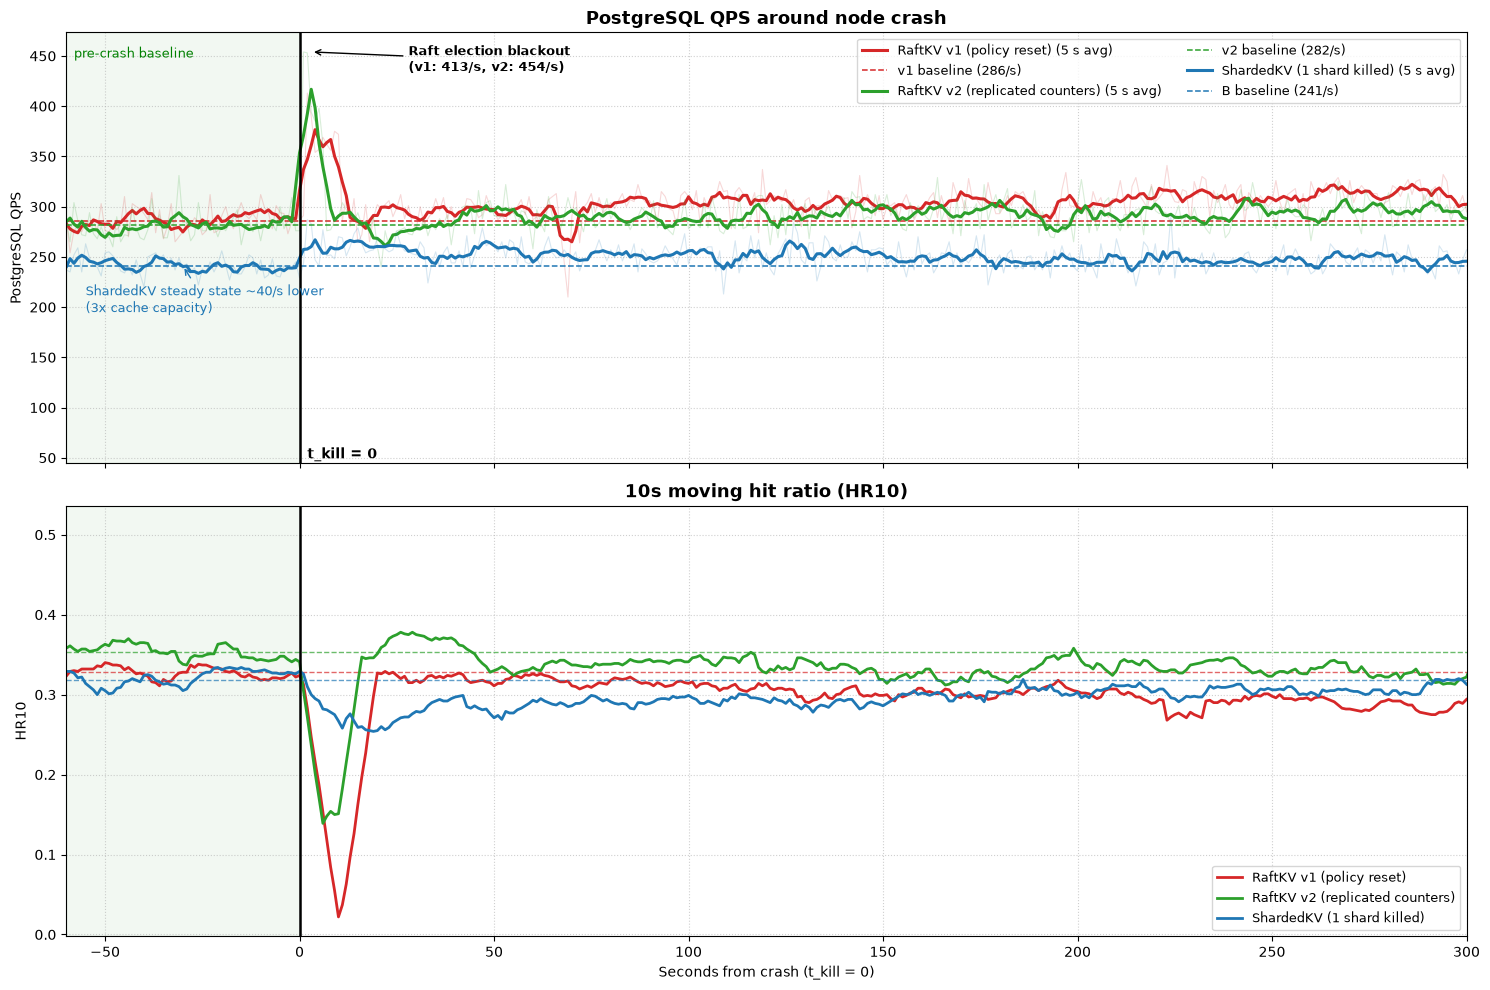

In [20]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

for k in ("v1", "v2", "B"):
    d = data[k]
    ax1.plot(d["t"], d["pg"], color=COLORS[k], alpha=0.18, linewidth=0.8)
    ax1.plot(d["t"], rolling(d["pg"]), color=COLORS[k], linewidth=2.2, label=f"{LABELS[k]} (5 s avg)")
    ax1.axhline(d["q_base"], color=COLORS[k], linestyle="--", linewidth=1.1,
                label=f"{k} baseline ({d['q_base']:.0f}/s)")
    ax2.plot(d["t"], d["hr10"], color=COLORS[k], linewidth=2, label=LABELS[k])
    ax2.axhline(d["hr_base"], color=COLORS[k], linestyle="--", linewidth=1.0, alpha=0.7)

for ax in (ax1, ax2):
    ax.axvline(0, color="black", linewidth=1.8)
    ax.axvspan(-60, 0, color="green", alpha=0.05)
    ax.grid(True, linestyle=":", alpha=0.6)

ax1.annotate("Raft election blackout\n(v1: 413/s, v2: 454/s)",
             xy=(3, 454), xytext=(28, 435), fontsize=9.5, fontweight="bold",
             arrowprops=dict(arrowstyle="->", color="black"))
ax1.annotate("ShardedKV steady state ~40/s lower\n(3x cache capacity)",
             xy=(-30, data["B"]["q_base"]), xytext=(-55, 195), fontsize=9.5, color=COLORS["B"],
             arrowprops=dict(arrowstyle="->", color=COLORS["B"]))
ax1.text(-58, ax1.get_ylim()[1] * 0.97, "pre-crash baseline", fontsize=9, va="top", color="green")
ax1.text(2, ax1.get_ylim()[0] + 5, "t_kill = 0", fontsize=10, fontweight="bold")

ax1.set_xlim(-60, OBSERVE_SEC)
ax1.set_ylabel("PostgreSQL QPS")
ax1.set_title("PostgreSQL QPS around node crash", fontsize=13, fontweight="bold")
ax1.legend(loc="upper right", fontsize=9, ncol=2)

ax2.set_xlabel("Seconds from crash (t_kill = 0)")
ax2.set_ylabel("HR10")
ax2.set_title("10s moving hit ratio (HR10)", fontsize=13, fontweight="bold")
ax2.legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

### Notes — Graph 1

- **Steady-state penalty (`t < 0`):** RaftKV v1 and v2 send `286/s` and `282/s` to PostgreSQL vs `241/s` for ShardedKV (`~40/s` more), because all 3 Raft nodes store the same keys while ShardedKV partitions capacity across 3 shards.
- **Election blackout (`t = 0–10s`):** RaftKV blocks `ReadIndex` until a new leader is elected (`5 s` in v2, `9 s` in v1). `HR10` drops to `0.022` (v1) and `0.139` (v2), spiking PostgreSQL to `413–454/s`. ShardedKV loses only 1/3 of the keyspace (`HR10` dips to `0.254`, PostgreSQL peaks at `291/s`).

## Graph 2: Excess PostgreSQL QPS Above Baseline (`Q(t) - Q_base`)

5 s rolling average of PostgreSQL QPS minus each run's own 120 s pre-crash baseline (`0` = pre-crash normal).

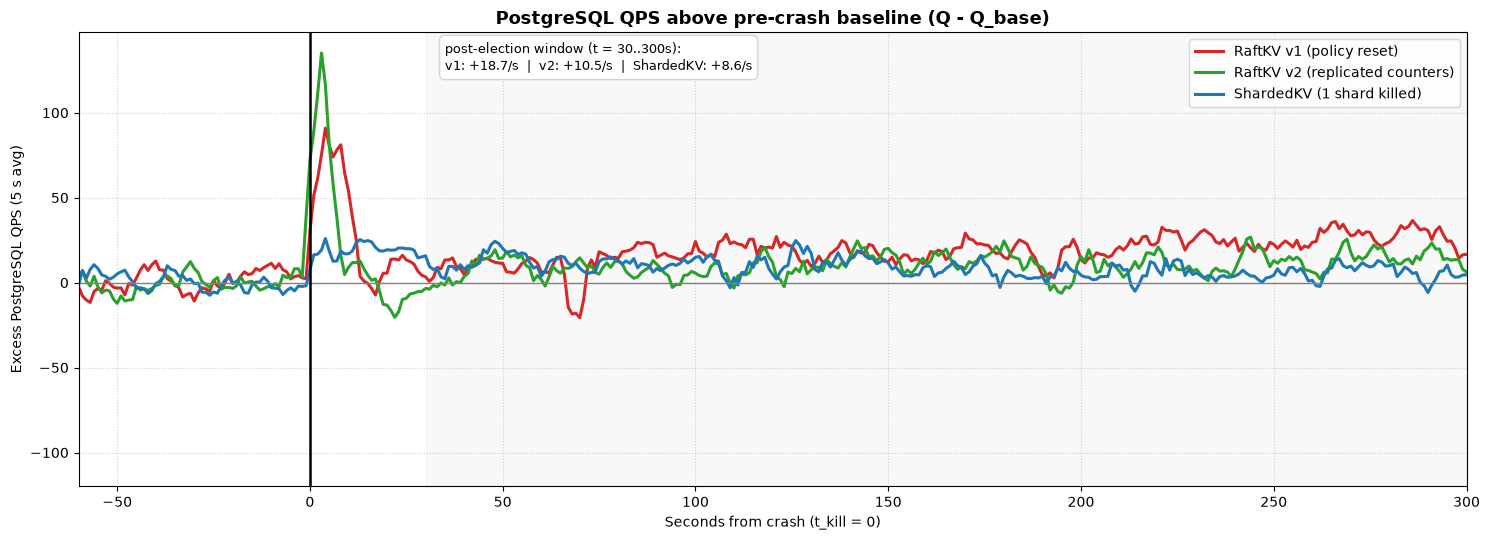

In [21]:
fig, ax = plt.subplots(figsize=(15, 5.5))

for k in ("v1", "v2", "B"):
    d = data[k]
    excess = [q - d["q_base"] for q in d["pg"]]
    ax.plot(d["t"], rolling(excess), color=COLORS[k], linewidth=2.2, label=LABELS[k])

ax.axhline(0, color="gray", linewidth=1)
ax.axvline(0, color="black", linewidth=1.8)
ax.axvspan(30, OBSERVE_SEC, color="gray", alpha=0.05)
ax.text(35, ax.get_ylim()[1] * 0.85, "post-election window (t = 30..300s):\nv1: +18.7/s  |  v2: +10.5/s  |  ShardedKV: +8.6/s",
        fontsize=9.5, bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="lightgray"))

ax.set_xlim(-60, OBSERVE_SEC)
ax.set_xlabel("Seconds from crash (t_kill = 0)")
ax.set_ylabel("Excess PostgreSQL QPS (5 s avg)")
ax.set_title("PostgreSQL QPS above pre-crash baseline (Q - Q_base)", fontsize=13, fontweight="bold")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right", fontsize=10)

plt.tight_layout()
plt.show()

### Notes — Graph 2

- **v1 policy-reset tail (`+18.7/s` over `t = 30–300s`):** In v1, the new leader has all keys in memory, but resets W-TinyLFU on promotion and evicts hot keys while rebuilding its frequency sketch.
- **v2 cuts post-election excess by 44% (`+10.5/s`):** Replicating hit counts through `ACCESS` entries preserves the frequency sketch and SLRU segments across leader changes, bringing RaftKV's post-election tail close to ShardedKV's refill curve (`+8.6/s`).

## Graph 3: Cumulative Extra PostgreSQL Queries (`Q_extra`)

Running sum of `Q(t) - Q_base` over `t = 0..300s`. Slope equals excess QPS; the value at `t = 300s` is `Q_extra_300`.

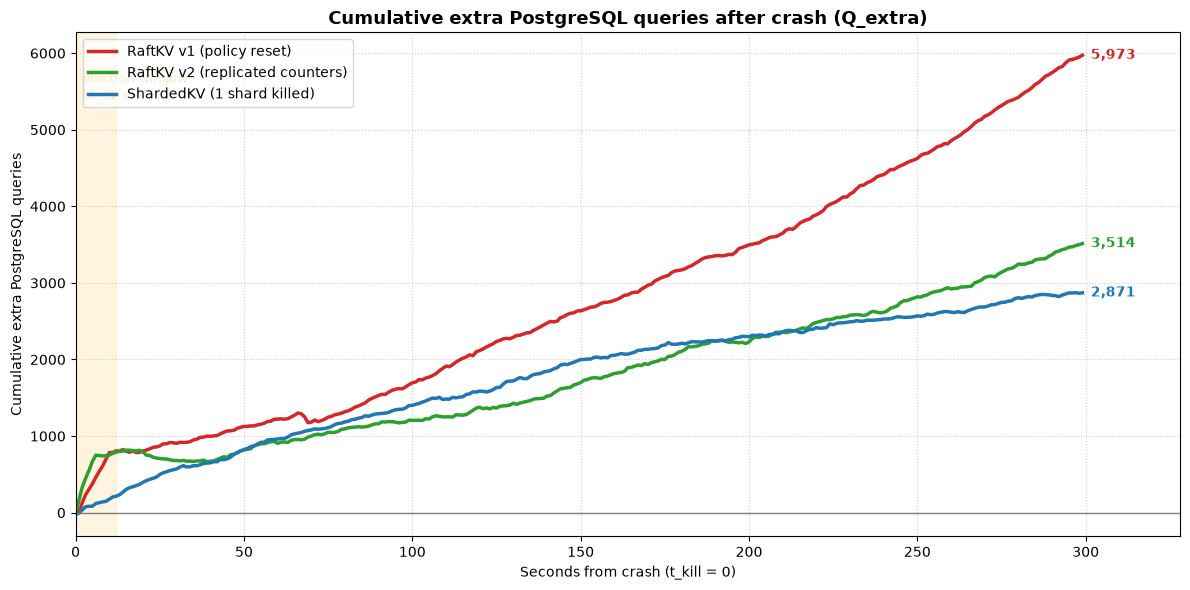

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))

for k in ("v1", "v2", "B"):
    ts, cum = cumulative_extra(data[k])
    ax.plot(ts, cum, color=COLORS[k], linewidth=2.5, label=LABELS[k])
    ax.annotate(f"{cum[-1]:,.0f}", xy=(ts[-1], cum[-1]), xytext=(6, 0),
                textcoords="offset points", color=COLORS[k], fontweight="bold", va="center")

ax.axhline(0, color="gray", linewidth=1)
ax.axvspan(0, 12, color="orange", alpha=0.12)
ax.text(2, 5400, "election window\n(0–12 s)", fontsize=9, color="darkorange")

ax.set_title("Cumulative extra PostgreSQL queries after crash (Q_extra)", fontsize=13, fontweight="bold")
ax.set_xlabel("Seconds from crash (t_kill = 0)")
ax.set_ylabel("Cumulative extra PostgreSQL queries")
ax.set_xlim(0, OBSERVE_SEC + 28)
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.show()

### Notes — Graph 3

- **Total failover cost (`Q_extra_300`):** `5,973` (RaftKV v1) → `3,514` (RaftKV v2, **−41%**) vs `2,871` (ShardedKV).
- **Where the gap comes from:** Over `t = 0–12s`, RaftKV v1 and v2 both pay the same election cost (`784` and `775` extra queries vs `205` for ShardedKV). After `t = 12s`, v1 diverges steeply while v2 tracks nearly parallel to ShardedKV.

## Summary Table

In [23]:
def summarize(d):
    post = [(x, q, h) for x, q, h in zip(d["t"], d["pg"], d["hr10"]) if 0 <= x < OBSERVE_SEC]
    peak = max(q for _, q, _ in post)
    extra_12 = sum(q - d["q_base"] for x, q, _ in post if x < 12)
    tail = [q for x, q, _ in post if x >= 30]
    tail_avg_extra = sum(tail) / len(tail) - d["q_base"]
    _, cum = cumulative_extra(d)
    meta = d["meta"]
    stale = (
        f"{meta['stale_reads_in_window']} / {meta['stale_reads_after_ack']}"
        if "stale_reads_in_window" in meta
        else f"{meta['total_stale_reads']} (total)"
    )
    return {
        "Baseline PG QPS": f"{d['q_base']:.0f}/s",
        "Baseline HR10": f"{d['hr_base']:.3f}",
        "Peak PG QPS": f"{peak}/s",
        "Lowest HR10": f"{min(h for _, _, h in post):.3f}",
        "Extra queries (0-12s)": f"{extra_12:,.0f}",
        "Mean excess QPS (30-300s)": f"{tail_avg_extra:+.1f}/s",
        "Q_extra_300 (0-300s)": f"{cum[-1]:,.0f}",
        "Stale reads (win / ack)": stale,
    }


rows = {k: summarize(data[k]) for k in ("v1", "v2", "B")}
header = f"{'Metric':<28} | {'RaftKV v1':>12} | {'RaftKV v2':>12} | {'ShardedKV':>12}"
print(header)
print("-" * len(header))
for m in rows["v1"]:
    print(f"{m:<28} | {rows['v1'][m]:>12} | {rows['v2'][m]:>12} | {rows['B'][m]:>12}")

Metric                       |    RaftKV v1 |    RaftKV v2 |    ShardedKV
-------------------------------------------------------------------------
Baseline PG QPS              |        286/s |        282/s |        241/s
Baseline HR10                |        0.328 |        0.353 |        0.318
Peak PG QPS                  |        413/s |        454/s |        291/s
Lowest HR10                  |        0.022 |        0.139 |        0.254
Extra queries (0-12s)        |          784 |          775 |          205
Mean excess QPS (30-300s)    |      +18.7/s |      +10.5/s |       +8.6/s
Q_extra_300 (0-300s)         |        5,973 |        3,514 |        2,871
Stale reads (win / ack)      |    2 (total) |        0 / 0 |        0 / 0


## Conclusion

1. **Replicating W-TinyLFU counters (v2) cut RaftKV's failover cost by 41%** (`Q_extra_300`: `5,973` → `3,514`) and reduced post-election excess QPS by **44%** (`+18.7/s` → `+10.5/s`). In v1, 87% of the extra database load came from resetting the eviction policy on promotion, not from the election itself.
2. **Election cost is unchanged (`~780` extra queries in `0–12s`).** While no leader exists, `ReadIndex` fails and all reads hit PostgreSQL. Election duration (`5–9s`) is set by Raft timers and is unaffected by eviction state.
3. **ShardedKV still outperforms RaftKV v2 during failover (`2,871` vs `3,514` extra queries) and in steady state (`241/s` vs `282/s`).** Losing 1 of 3 independent shards drops only 1/3 of cached keys with zero election stall, and partitioning gives 3× the total cache capacity of a 3-node replicated group.
4. **Stale reads:** v1 recorded 2 stale reads at `t = +11s` (queued `DELETE` retries racing with reads on the new warm leader); v2 and ShardedKV recorded `0 / 0`.
5. **Architectural takeaway:** Full-cluster Raft replication is the wrong topology for a cache-aside layer—it trades away 2/3 of cache capacity and stalls the entire keyspace during elections. **Multi-Raft** (sharded keyspace with per-shard Raft groups) is needed to combine shard-level capacity scaling with warm failover (limiting any election to `1/N` of keys).
6. **Measurement caveats:** `n = 1` trial per system on `kind`. Both v2 and ShardedKV remain `+8.6` to `+10.5/s` above pre-crash baseline at `t = 300s`; a no-failure control run is required to separate workload drift from true failover cost.